In [2]:
import scanpy as sc
import squidpy as sq

from gctsvg.preprocessing import common

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)


In [105]:
adata_st = sc.read("data_repo/Mouse Cerebellum/rodriques_slideseq.h5ad")

In [106]:
adata_st

AnnData object with n_obs × n_vars = 32701 × 6942
    obsm: 'spatial'

In [107]:
is_mt_gene = lambda adata: adata_st.var.index.str.startswith("mt-")
adata_st = common.filter(adata_st, min_locs=50, min_genes=20, is_mt_gene=is_mt_gene)
adata_st

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:170: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_genes"] = number


AnnData object with n_obs × n_vars = 21848 × 6601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    obsm: 'spatial'

In [108]:
common.compute_hvgs(adata_st)
adata_st = adata_st[:, adata_st.var['highly_variable']]
adata_st

View of AnnData object with n_obs × n_vars = 21848 × 3000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    obsm: 'spatial'

In [109]:
sc.write("data_repo/Mouse Cerebellum/adata_preprocessed.h5ad", adata_st)

## Representation Learning
```bash
python RepresentationLearning.py --project "Mouse Cerebellum" \
--data.filename "data_repo/Mouse Cerebellum/adata_preprocessed.h5ad" \
--data.preprocess \
--model.n_in 3000 --model.n_out 200 \
--trainer.accelerator gpu --trainer.strategy ddp --trainer.num_nodes 1 --trainer.devices 4 \
--trainer.num_epochs 1000 --trainer.batch_size 5462
```
## Clustering
```bash
python Clustering.py --project "Mouse Cerebellum" \
--resolution 0.05
```

In [15]:
adata_clusters_filename = "gctsvg_output/Mouse Cerebellum/clustering/adata_clusters.h5ad"
adata_clusters = sc.read(adata_clusters_filename)

In [16]:
adata_clusters

AnnData object with n_obs × n_vars = 21848 × 3000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors'
    obsm: 'embedding', 'spatial'
    layers: 'original', 'reconstruction'
    obsp: 'connectivities', 'distances'

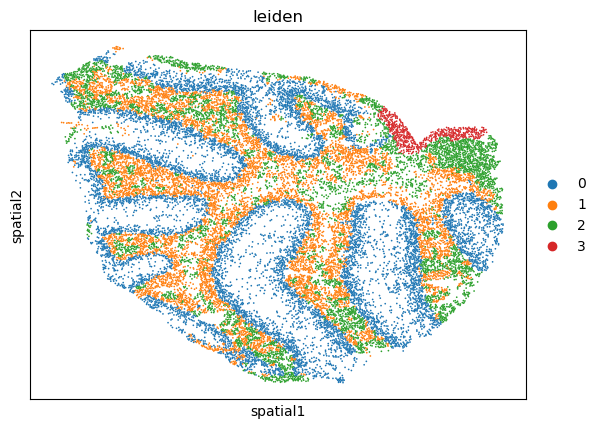

In [17]:
adata_clusters.obsm["spatial"] = adata_clusters.obsm["spatial"].to_numpy()
sc.pl.embedding(adata_clusters, s=6, basis='spatial', color='leiden')

In [9]:
adata_clusters

AnnData object with n_obs × n_vars = 21848 × 3000
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden', 'log1p', 'neighbors', 'leiden_colors'
    obsm: 'embedding', 'spatial'
    layers: 'original', 'reconstruction'
    obsp: 'connectivities', 'distances'

In [10]:
adata_clusters.obsm['embedding']

array([[-4.87192720e-01, -7.83288758e-03, -1.17986254e-01, ...,
        -6.96301460e-01,  2.64889318e-02,  2.34040059e-03],
       [-5.37123978e-01, -5.44834649e-04, -1.27936780e-01, ...,
        -7.67481327e-01,  2.27281395e-02,  9.53269470e-03],
       [-7.28576183e-01,  5.35140820e-02, -9.25531685e-02, ...,
        -9.41904306e-01,  2.33392715e-02,  4.11655679e-02],
       ...,
       [-5.00818968e-01, -2.11901255e-02, -1.41299650e-01, ...,
        -7.34505117e-01,  3.47457901e-02,  3.33416183e-03],
       [-5.23316681e-01, -9.61323921e-03, -1.35005951e-01, ...,
        -7.47226596e-01,  2.59707663e-02,  9.26591735e-03],
       [-5.50519168e-01, -1.86926257e-02, -1.46793514e-01, ...,
        -7.96625972e-01,  2.24657524e-02, -7.13184476e-04]], dtype=float32)

In [11]:
import torch
adata_clusters.obs['leiden'].apply(int)

barcodes
TTCGTTATTTTTTT    0
CAAACCAACCCCCC    2
CGCTGGTAGGGGGN    3
CACTTCTATTTTTT    0
CGAGGCCATTTTTT    0
                 ..
ATAACCATCGCGCT    1
AGTACGCTGCGGCT    2
GTGACTGTTATATA    2
CTGCGAATCGCGAT    2
AAGCCCATCGCGCN    2
Name: leiden, Length: 21848, dtype: category
Categories (4, int64): [0, 1, 2, 3]

In [ ]:
adata_clus

In [192]:
from gctsvg.pipeline.embedding import STDataModule

In [194]:
batch_size = 512
dm = STDataModule(adata_clusters, "Mouse Cerebellum", batch_size=batch_size, num_workers=1)

In [200]:
dm.setup(stage="predict")
loader = dm.train_dataloader()
loader_iter = iter(loader)

In [201]:
nodes = next(loader_iter)

In [202]:
nodes

Data(num_nodes=504, edge_index=[2, 260], x=[504, 3000], node_norm=[504], edge_norm=[260])

In [204]:
nodes.edge_index

tensor([[  1,   1,   2,   3,   7,  11,  11,  12,  13,  16,  16,  16,  17,  17,
          19,  21,  27,  28,  32,  35,  36,  37,  38,  40,  42,  43,  44,  47,
          47,  48,  51,  52,  53,  55,  55,  56,  57,  58,  60,  62,  64,  64,
          64,  67,  67,  69,  70,  71,  72,  74,  74,  76,  76,  77,  82,  83,
          85,  86,  88,  89,  91,  91,  93,  94,  94,  96, 101, 101, 104, 105,
         106, 108, 109, 109, 111, 114, 118, 123, 124, 125, 128, 129, 132, 139,
         140, 141, 141, 144, 150, 158, 162, 165, 168, 169, 169, 169, 170, 172,
         179, 180, 182, 182, 183, 184, 190, 190, 199, 199, 199, 200, 201, 202,
         203, 204, 205, 207, 208, 210, 211, 211, 213, 213, 215, 217, 220, 225,
         226, 227, 232, 233, 239, 240, 241, 241, 244, 245, 249, 252, 254, 255,
         255, 256, 261, 261, 263, 265, 266, 266, 268, 268, 271, 273, 275, 276,
         279, 280, 281, 283, 287, 288, 289, 290, 297, 300, 301, 303, 304, 306,
         307, 312, 315, 318, 319, 320, 328, 332, 333